<a href="https://colab.research.google.com/github/FatherNurt/FPDP-Engine/blob/MAIN/Maxwell_Wigner_Correspondence_Lab_v0_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maxwell–Wigner Correspondence Lab v0.1
Magnetotunneling–Velocity v2.0 | preliminary control | 27 November 2026

Original hypothesis: $\tau_{MT}=\kappa d/\omega$. Test against $\tau_W=\mathrm{Im}(t'/t)$ using $e^{-i\omega t}$ and face-to-face reference planes. Ideal scalar Helmholtz barrier, identical TEM-like ports, equal permeability, continuity of field and derivative. Not a full stepped waveguide or magnetic-material model. No empirical data or FUNt scaling. Parameters selected for demonstration, not fitted.

With $\beta=\omega/c$, $\kappa=\sqrt{\omega_c^2-\omega^2}/c$, boundary matching gives $t=[\cosh(\kappa d)+iQ\sinh(\kappa d)]^{-1}$, $Q=(\kappa/\beta-\beta/\kappa)/2$. The corresponding reflection is $r=-i(\kappa/\beta+\beta/\kappa)\sinh(\kappa d)t/2$. The code uses a scaled expression for numerical stability. Valid for $0<\omega<\omega_c$, $d\ge0$.

Reference: H. G. Winful, Phys. Rev. E 68, 016615 (2003), https://doi.org/10.1103/PhysRevE.68.016615 .

In [1]:
import numpy as np
from scipy.optimize import brentq
c=299792458.; f0=10e9; w0=2*np.pi*f0; wcut=2*np.pi*12e9
# TEM ports and ideal TE-like scalar barrier, equal permeability; continuity E,E'
def model(w,d):
    b=w/c; k=np.sqrt(wcut**2-w**2)/c
    q=(k/b-b/k)/2
    u=k*d; h=np.tanh(u)
    t=2*np.exp(-u)/(1+np.exp(-2*u))/(1+1j*q*h)
    qp=-(k/b+b/k)*wcut**2/(2*w*(wcut**2-w**2))
    kp=-w/(c*c*k)
    tau=-(qp*h+q*d*kp*(1-h*h))/(1+(q*h)**2)
    return t,tau,k*d/w,k,q


In [2]:
# Independent boundary matching and derivative checks
# Solve E(0)=1+r, E'(0)=i*b*(1-r), E(d)=t, E'(d)=i*b*t
# Use decaying amplitudes from each face to avoid growing exponentials.
def direct(w,d):
    b=w/c; k=np.sqrt(wcut**2-w**2)/c; e=np.exp(-k*d)
    A=np.array([[1,e,-1,0],[-k,k*e,1j*b,0],[e,1,0,-1],[-k*e,k,0,-1j*b]],complex)
    a,g,r,t=np.linalg.solve(A,[1,1j*b,0,0])
    return r,t
max_t=max_energy=max_delay=0.
for f in np.linspace(2e9,11.8e9,25):
    w=2*np.pi*f
    for d in np.geomspace(.001,.1,20):
        t,tau,mt,k,q=model(w,d); r,td=direct(w,d)
        max_t=max(max_t,abs(t-td))
        max_energy=max(max_energy,abs(abs(r)**2+abs(t)**2-1))
        h=w*1e-5
        fd=np.angle(model(w+h,d)[0]/model(w-h,d)[0])/(2*h)
        max_delay=max(max_delay,abs(fd-tau)/max(abs(tau),1e-15))
print('Max complex t error:',max_t,'Max energy error:',max_energy,'Max relative derivative error:',max_delay)
assert max_t<1e-12 and max_energy<1e-12 and max_delay<1e-5
assert abs(model(w0,0)[0]-1)<1e-14 and model(w0,0)[1]==0
# Opaque limit: -Qprime/(1+Q^2)=2/sqrt(wcut^2-w^2)
assert np.isclose(model(w0,.1)[1],2/np.sqrt(wcut**2-w0**2),rtol=1e-8)
print('All control checks PASS')

Max complex t error: 1.0017302167071694e-14 Max energy error: 3.9968028886505635e-15 Max relative derivative error: 4.1182416526303457e-08
All control checks PASS


d mm | T | Wigner ps | MT ps | ratio
   1.0 0.97759533 5.708149 2.212614 2.579822
   5.0 0.59985124 25.569889 11.063069 2.311283
  10.0 0.19308345 39.742731 22.126139 1.796189
  20.0 0.01298516 47.178297 44.252278 1.066121
  50.0 3.1129415e-06 47.986629 110.630695 0.433755
 100.0 2.854272e-12 47.987021 221.261389 0.216879
Equality (mm): 21.43006012982163 Power transmission: 0.008740312277574536
Grid points within 5%: 286 / 12000


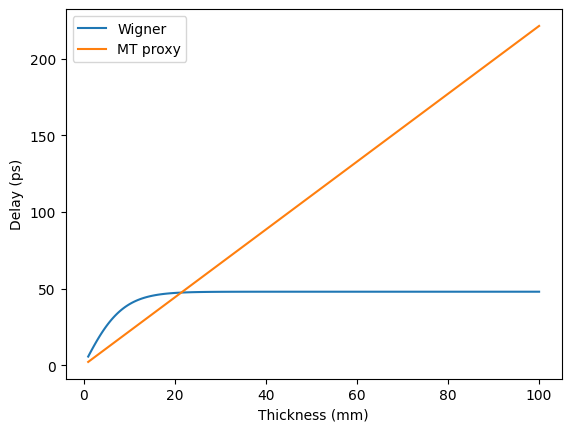

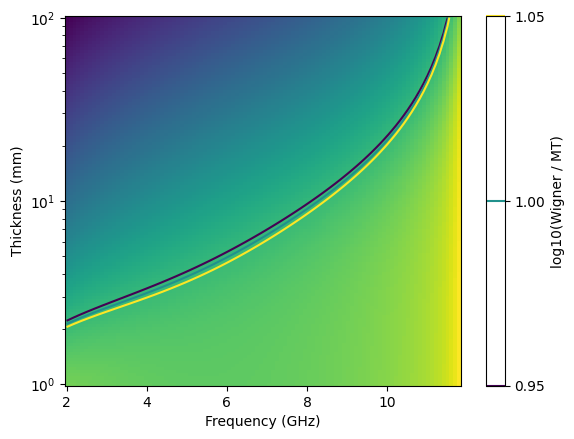

In [3]:
print('d mm | T | Wigner ps | MT ps | ratio')
for d in [.001,.005,.01,.02,.05,.1]:
    t,a,b,k,q=model(w0,d); print(f'{d*1e3:6.1f} {abs(t)**2:.8g} {a*1e12:.6f} {b*1e12:.6f} {a/b:.6f}')
root=brentq(lambda d:model(w0,d)[1]-model(w0,d)[2],.001,.2,xtol=1e-14)
print('Equality (mm):',root*1000,'Power transmission:',abs(model(w0,root)[0])**2)
# Frequency/thickness map: exploratory, 5% tolerance not a preregistered physical acceptance criterion.
fs=np.linspace(2e9,11.8e9,100); ds=np.geomspace(.001,.1,120)
W,D=np.meshgrid(2*np.pi*fs,ds)
t,a,b,k,q=model(W,D); ratio=a/b
mask=np.abs(ratio-1)<=.05
print('Grid points within 5%:',mask.sum(),'/',mask.size)
import matplotlib.pyplot as plt
plt.figure(); plt.plot(ds*1000,model(w0,ds)[1]*1e12,label='Wigner'); plt.plot(ds*1000,model(w0,ds)[2]*1e12,label='MT proxy'); plt.xlabel('Thickness (mm)'); plt.ylabel('Delay (ps)'); plt.legend(); plt.show()
plt.figure(); plt.pcolormesh(fs/1e9,ds*1000,np.log10(ratio),shading='auto'); plt.contour(fs/1e9,ds*1000,ratio,levels=[.95,1,1.05]); plt.yscale('log'); plt.colorbar(label='log10(Wigner / MT)'); plt.xlabel('Frequency (GHz)'); plt.ylabel('Thickness (mm)'); plt.show()

## Disposition
MT is an attenuation-derived velocity-dimensional proxy, not a general delay velocity. Isolated equality is not a physical validation. Next: independent audit of scalar control, then a dispersive passive magnetic constitutive model and full boundary matching, checking loss and bias reversal. C9 geometry dynamics require a separate force/stress and material-response law. No experimental or gravitational claims.